In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(r"C:\Users\hp\Downloads\emails.csv")

print("Dataset Loaded Successfully")
print("Shape:", df.shape)

df.head()

Dataset Loaded Successfully
Shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [4]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB

Column Names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'te

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Missing Values:
0

Duplicate Rows:
0


In [5]:
df = df.drop_duplicates()

df = df.fillna(0)

print("Missing Values After Cleaning:", df.isnull().sum().sum())
print("Dataset Shape After Cleaning:", df.shape)

Missing Values After Cleaning: 0
Dataset Shape After Cleaning: (5172, 3002)


In [6]:
X = df.drop(['Email No.', 'Prediction'], axis=1)
y = df['Prediction']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nClass Distribution:")
print(y.value_counts())

Features Shape: (5172, 3000)
Target Shape: (5172,)

Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


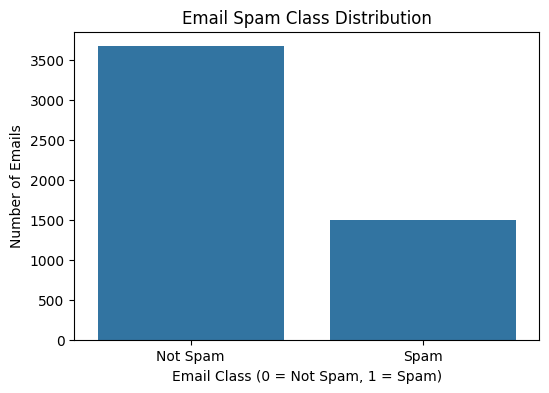

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.title("Email Spam Class Distribution")
plt.xlabel("Email Class (0 = Not Spam, 1 = Spam)")
plt.ylabel("Number of Emails")

plt.xticks([0, 1], ["Not Spam", "Spam"])
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [9]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [10]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Classification Completed")

KNN Classification Completed


In [11]:
print("KNN Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["Not Spam", "Spam"]
))

KNN Classification Report:

              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



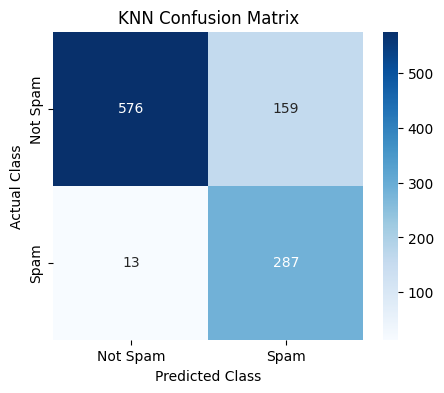

In [12]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [13]:
svm = SVC(kernel='linear', random_state=42)

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Classification Completed")

SVM Classification Completed


In [14]:
print("SVM Classification Report:\n")

print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Not Spam", "Spam"]
))

SVM Classification Report:

              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



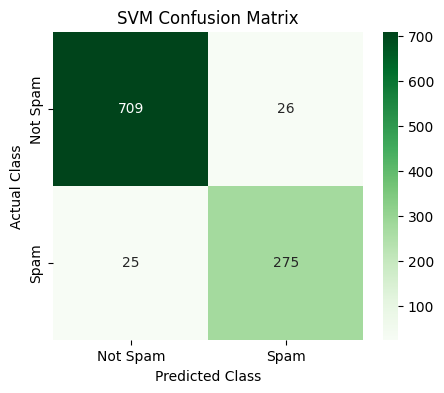

In [15]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [16]:
results = pd.DataFrame({
    'Algorithm': ['KNN', 'SVM'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],

    'Precision': [
        precision_score(y_test, y_pred_knn, zero_division=0),
        precision_score(y_test, y_pred_svm, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, y_pred_knn, zero_division=0),
        recall_score(y_test, y_pred_svm, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_knn, zero_division=0),
        f1_score(y_test, y_pred_svm, zero_division=0)
    ]
})

print("Performance Comparison:")
display(results.round(4))

Performance Comparison:


,Algorithm,Accuracy,Precision,Recall,F1 Score
0,KNN,0.8338,0.6435,0.9567,0.7694
1,SVM,0.9507,0.9136,0.9167,0.9151


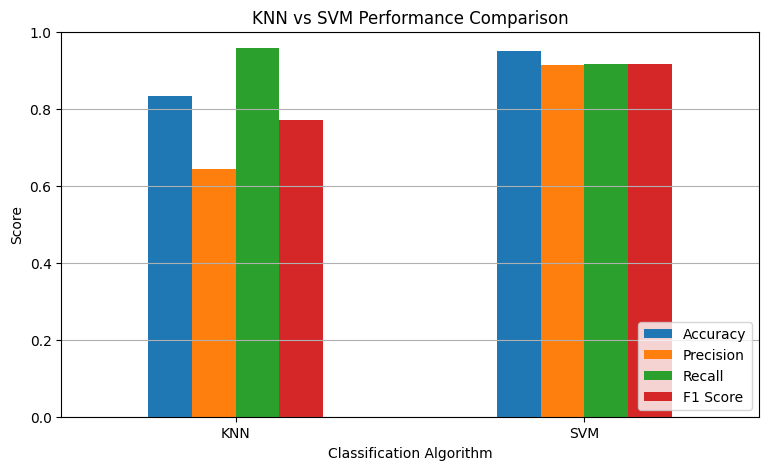

In [17]:
results.set_index('Algorithm').plot(
    kind='bar',
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.legend(loc='lower right')
plt.grid(axis='y')

plt.show()

In [18]:
best_model = results.loc[
    results['F1 Score'].idxmax()
]

print("Best Performing Algorithm:", best_model['Algorithm'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))

Best Performing Algorithm: SVM
Accuracy: 0.9507
Precision: 0.9136
Recall: 0.9167
F1 Score: 0.9151


In [19]:
sample_email = X.iloc[[0]]

sample_scaled = scaler.transform(sample_email)

knn_prediction = knn.predict(sample_scaled)[0]
svm_prediction = svm.predict(sample_scaled)[0]

print("KNN Prediction:",
      "Spam" if knn_prediction == 1 else "Not Spam")

print("SVM Prediction:",
      "Spam" if svm_prediction == 1 else "Not Spam")

KNN Prediction: Not Spam
SVM Prediction: Not Spam


In [20]:
print("========== FINAL RESULT ==========")

print("\nKNN Accuracy:",
      round(accuracy_score(y_test, y_pred_knn) * 100, 2), "%")

print("SVM Accuracy:",
      round(accuracy_score(y_test, y_pred_svm) * 100, 2), "%")

print("\nBest Model:",
      results.loc[results['F1 Score'].idxmax(), 'Algorithm'])

print("\nEmail Spam Detection Completed Successfully!")

========== FINAL RESULT ==========

KNN Accuracy: 83.38 %
SVM Accuracy: 95.07 %

Best Model: SVM

Email Spam Detection Completed Successfully!
